# Horizon vs grid coverage

The supervised path is the robot's future trajectory expressed in the **ego frame** of
the anchor pose (translate by anchor position, de-rotate by anchor yaw), exactly as
`dataloader.get_states` does. `trav_criterion` then **masks** any path point that falls
outside the BEV grid (`xbound`/`ybound`).

At ANYmal's slow pace the inherited `HORIZON=300` (30 s) overshoots the 8 m forward map,
so a large fraction of path points are masked. This notebook quantifies that:

1. **Coverage curve + table** over all missions: how much of an `H`-step window lands in-grid.
2. **Spatial plots**: the grid box vs the actual future path, for a few example anchors
   and a few horizons.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.spatial.transform import Rotation as R, Slerp

DATA_ROOT = Path("/datahome/lmertens/grand_tour_dataset/output")
DT = 0.1
HMAX = 300

# Grid bounds from configs/grandtour.yaml (must match training).
XB = (-2.0, 8.0)
YB = (-5.0, 5.0)


def load_poses(d: Path) -> np.ndarray | None:
    """(N,3) [x, y, yaw] cpt7 ground-truth pose on the RHE timestamp grid, or None.

    Mirrors GrandTourDataset._interp_cpt7: linear-interp cpt7 x,y and slerp yaw
    onto the (sorted) RHE timestamps, clamped to the cpt7 time range.
    """
    if not ((d / "cpt7_odom.npy").exists() and (d / "timestamp.npy").exists()):
        return None
    ts = np.sort(np.load(d / "timestamp.npy").astype(float))
    cpt7 = np.load(d / "cpt7_odom.npy")
    t = cpt7[:, 0]
    o = np.argsort(t)
    t, pos, quat = t[o], cpt7[o, 1:3], cpt7[o, 4:8]
    t, u = np.unique(t, return_index=True)
    pos, quat = pos[u], quat[u]
    cl = np.clip(ts, t[0], t[-1])
    x = np.interp(cl, t, pos[:, 0])
    y = np.interp(cl, t, pos[:, 1])
    yaw = Slerp(t, R.from_quat(quat[:, [1, 2, 3, 0]]))(cl).as_euler("zyx")[:, 0]
    return np.column_stack((x, y, yaw))


def to_ego(poses: np.ndarray, anchor: int, h: int) -> np.ndarray:
    """Future poses[anchor:anchor+h] in the anchor's ego frame (get_states transform)."""
    sl = poses[anchor : anchor + h]
    dx, dy = sl[:, 0] - poses[anchor, 0], sl[:, 1] - poses[anchor, 1]
    th = poses[anchor, 2]
    c, s = np.cos(th), np.sin(th)
    return np.stack((c * dx + s * dy, -s * dx + c * dy), axis=1)


def in_grid(xy: np.ndarray) -> np.ndarray:
    return (xy[:, 0] >= XB[0]) & (xy[:, 0] <= XB[1]) & (xy[:, 1] >= YB[0]) & (xy[:, 1] <= YB[1])


missions = sorted(
    p.name for p in DATA_ROOT.iterdir() if p.is_dir() and (p / "cpt7_odom.npy").exists()
)
missions = [m for m in missions if m != "ICE-1"]  # unreliable data
print(len(missions), "missions with poses")

1 missions with poses


## Coverage over all missions

For each step offset `k` (0..HMAX), the **marginal in-grid probability** = over every
valid anchor in every mission, the fraction whose pose at offset `k` lands in the grid.
`coverage(H)` is then the mean of that curve over the first `H` steps: the expected
fraction of an `H`-step supervised window that is actually used (not masked).

In [2]:
# Marginal in-grid count per step offset, pooled over all anchors and missions.
hits = np.zeros(HMAX)
tot = np.zeros(HMAX)

for m in missions:
    p = load_poses(DATA_ROOT / m)
    xy, yaw = p[:, :2], p[:, 2]
    n = len(p)
    for k in range(HMAX):
        if k >= n:
            break
        a = slice(0, n - k)  # valid anchors for this offset
        dx = xy[k:, 0] - xy[a, 0]
        dy = xy[k:, 1] - xy[a, 1]
        c, s = np.cos(yaw[a]), np.sin(yaw[a])
        xr = c * dx + s * dy
        yr = -s * dx + c * dy
        ok = (xr >= XB[0]) & (xr <= XB[1]) & (yr >= YB[0]) & (yr <= YB[1])
        hits[k] += ok.sum()
        tot[k] += ok.size

marginal = hits / tot  # P(pose at offset k is in grid)
coverage = np.cumsum(marginal) / np.arange(1, HMAX + 1)  # mean over first H steps

In [3]:
import pandas as pd

cands = [50, 100, 130, 150, 200, 250, 300]
tbl = pd.DataFrame({
    "HORIZON": cands,
    "seconds": [h * DT for h in cands],
    "marginal_at_H_%": [round(100 * marginal[h - 1], 1) for h in cands],
    "window_coverage_%": [round(100 * coverage[h - 1], 1) for h in cands],
    "used_steps": [round(coverage[h - 1] * h, 1) for h in cands],
}).set_index("HORIZON")
print("marginal_at_H   : P(the H-th step itself is in-grid)")
print("window_coverage : mean fraction of the 0..H window that is in-grid (= used supervision)")
print("used_steps      : window_coverage * H  (effective supervised steps)")
tbl

marginal_at_H   : P(the H-th step itself is in-grid)
window_coverage : mean fraction of the 0..H window that is in-grid (= used supervision)
used_steps      : window_coverage * H  (effective supervised steps)


,seconds,marginal_at_H_%,window_coverage_%,used_steps
HORIZON,,,,
50,5.0,100.0,100.0,50.0
100,10.0,56.8,95.4,95.4
130,13.0,30.8,82.6,107.4
150,15.0,24.6,75.2,112.8
200,20.0,13.4,61.2,122.5
250,25.0,8.5,51.0,127.6
300,30.0,5.7,43.7,131.2


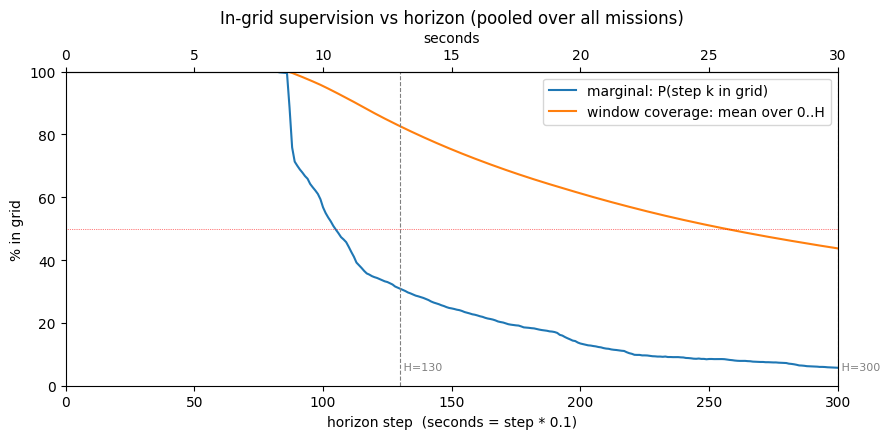

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
steps = np.arange(1, HMAX + 1)
ax.plot(steps, 100 * marginal, label="marginal: P(step k in grid)")
ax.plot(steps, 100 * coverage, label="window coverage: mean over 0..H")
for h in [130, 300]:
    ax.axvline(h, color="grey", ls="--", lw=0.8)
    ax.text(h, 5, f" H={h}", fontsize=8, color="grey")
ax.axhline(50, color="red", lw=0.5, ls=":")
ax.set_xlabel("horizon step  (seconds = step * 0.1)")
ax.set_ylabel("% in grid")
ax.set_title("In-grid supervision vs horizon (pooled over all missions)")
ax.set_xlim(0, HMAX)
ax.set_ylim(0, 100)
secax = ax.secondary_xaxis("top", functions=(lambda s: s * DT, lambda t: t / DT))
secax.set_xlabel("seconds")
ax.legend()
fig.tight_layout()
plt.show()

## Spatial view: grid box vs future path

For a few example anchors, the grid rectangle vs the future path in the anchor's ego
frame. The path is split into three horizon bands so it's visible where each candidate
`HORIZON` leaves the map. Points outside the box are exactly what `trav_criterion` masks.

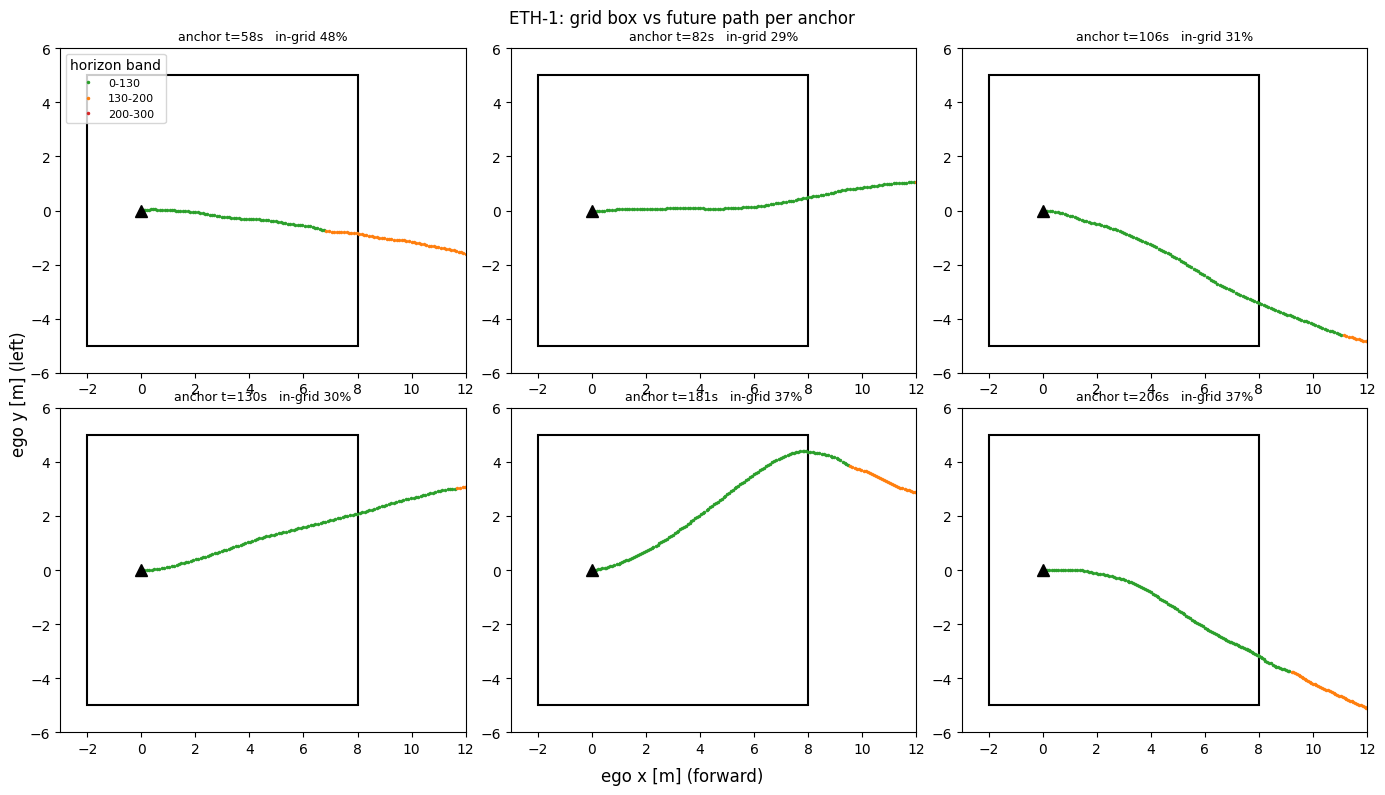

In [5]:
VIS_MISSION = "ETH-1"  # the mission with images
HBANDS = [(0, 130, "tab:green"), (130, 200, "tab:orange"), (200, 300, "tab:red")]

poses = load_poses(DATA_ROOT / VIS_MISSION)
valid = np.arange(0, len(poses) - HMAX)
# Prefer anchors where the robot actually moves over the window.
disp = np.linalg.norm(poses[valid + HMAX, :2] - poses[valid, :2], axis=1)
moving = valid[disp > np.median(disp)]
anchors = moving[np.linspace(0, len(moving) - 1, 6).astype(int)]

fig, axes = plt.subplots(2, 3, figsize=(14, 8), squeeze=False)
for ax, anch in zip(axes.flat, anchors):
    xy = to_ego(poses, anch, HMAX)
    for lo, hi, col in HBANDS:
        seg = xy[lo:hi]
        ax.plot(seg[:, 0], seg[:, 1], ".", ms=3, color=col, label=f"{lo}-{hi}")
    ax.add_patch(Rectangle((XB[0], YB[0]), XB[1] - XB[0], YB[1] - YB[0],
                           fill=False, ec="k", lw=1.5))
    ing = in_grid(xy)
    ax.set_title(f"anchor t={anch * DT:.0f}s   in-grid {100 * ing.mean():.0f}%", fontsize=9)
    ax.plot(0, 0, "k^", ms=8)  # robot
    ax.set_aspect("equal")
    ax.set_xlim(XB[0] - 1, XB[1] + 4)
    ax.set_ylim(YB[0] - 1, YB[1] + 1)
axes.flat[0].legend(title="horizon band", fontsize=8, loc="upper left")
fig.supxlabel("ego x [m] (forward)")
fig.supylabel("ego y [m] (left)")
fig.suptitle(f"{VIS_MISSION}: grid box vs future path per anchor")
fig.tight_layout()
plt.show()